# Exploração da base de jogadores

Este notebook faz uma leitura exploratória da amostra já validada pelo projeto. Ele não substitui o pipeline: os índices e percentis são carregados dos arquivos processados para permitir conferência, visualização e discussão das limitações.

**Pergunta do estudo:** a academia de formação ajuda a explicar o perfil técnico e explosivo dos jogadores que revela?

A unidade de análise é o jogador. A amostra contempla quatro academias e tem tamanho reduzido e desigual, por isso os gráficos são descritivos.

In [5]:
from pathlib import Path

import pandas as pd
import plotly.express as px
from IPython.display import Image, display

RAIZ = Path.cwd()
if not (RAIZ / "data").exists() and (RAIZ.parent / "data").exists():
    RAIZ = RAIZ.parent

DIR_PROCESSADOS = RAIZ / "data" / "processed"
indices = pd.read_csv(DIR_PROCESSADOS / "indices_jogadores.csv")
percentis = pd.read_csv(DIR_PROCESSADOS / "percentis_metricas.csv")
cobertura = pd.read_csv(DIR_PROCESSADOS / "cobertura_metricas.csv")

print(f"Jogadores: {indices['player_id'].nunique()}")
print(f"Academias: {indices['clube'].nunique()}")
display(indices.head())

Jogadores: 35
Academias: 4


,clube,player_id,nome,position,sub_position,date_of_birth,height_in_cm,estreia,minutos,jogos,...,url,formado_confirmado,fonte_conferencia,categoria,indice_explosivo,indice_tecnico,cobertura_explosivo,cobertura_tecnico,n_metricas_explosivo,n_metricas_tecnico
0,Barcelona,636688,Alejandro Balde,Defender,Left-Back,2003-10-18,177.0,2021-09-14,11618,168,...,https://www.transfermarkt.co.uk/alejandro-bald...,sim,(conhecimento previo): La Masia desde a infancia,lateral,47.523810,50.937500,1.0,1.0,6,7
1,Barcelona,937958,Lamine Yamal,Attack,Right Winger,2007-07-13,183.0,2023-04-29,11219,151,...,https://www.transfermarkt.co.uk/lamine-yamal/p...,sim,(conhecimento previo): La Masia desde 2013,meia_ofensivo_ponta,56.870748,35.625000,1.0,1.0,6,7
2,Barcelona,646740,Gavi,Midfield,Central Midfield,2004-08-05,173.0,2021-08-29,10176,166,...,https://www.transfermarkt.co.uk/gavi/profil/sp...,sim,(conhecimento previo): La Masia desde a infancia,meio_campista_defensivo_central,53.741497,55.089286,1.0,1.0,6,7
3,Barcelona,962110,Pau Cubarsí,Defender,Centre-Back,2007-01-22,184.0,2024-01-18,10119,128,...,https://www.transfermarkt.co.uk/pau-cubarsi/pr...,sim,(conhecimento previo): La Masia desde a infancia,zagueiro,57.619048,50.208333,1.0,1.0,6,7
4,Barcelona,636703,Fermín López,Midfield,Attacking Midfield,2003-05-11,176.0,2023-08-27,6993,136,...,https://www.transfermarkt.co.uk/fermin-lopez/p...,sim,(conhecimento previo): entrou na La Masia por...,meia_ofensivo_ponta,60.884354,55.089286,1.0,1.0,6,7


## Composição da amostra

Primeiro verificamos quantos atletas há em cada academia e como as posições estão distribuídas. Essas contagens contextualizam todas as comparações posteriores: os grupos não têm o mesmo tamanho.

In [2]:
contagem_academias = (
    indices.groupby("clube", as_index=False)["player_id"]
    .nunique()
    .rename(columns={"player_id": "jogadores"})
    .sort_values("jogadores", ascending=False)
)
contagem_posicoes = (
    indices.groupby(["clube", "categoria"], as_index=False)["player_id"]
    .nunique()
    .rename(columns={"player_id": "jogadores"})
)

display(contagem_academias)
display(contagem_posicoes.pivot(index="categoria", columns="clube", values="jogadores").fillna(0).astype(int))

,clube,jogadores
0,Barcelona,15
1,Liverpool,8
2,Manchester City,7
3,Real Madrid,5


clube,Barcelona,Liverpool,Manchester City,Real Madrid
categoria,,,,
centroavante,0,0,0,2
goleiro,1,1,1,0
lateral,3,3,2,2
meia_ofensivo_ponta,3,1,3,0
meio_campista_defensivo_central,6,1,0,0
zagueiro,2,2,1,1


## Distribuição dos índices

Os índices vão de 0 a 100 e representam médias ponderadas de percentis calculados dentro de grupos posicionais. Portanto, descrevem a posição relativa dos atletas na amostra usada no cálculo, não uma nota universal de qualidade.

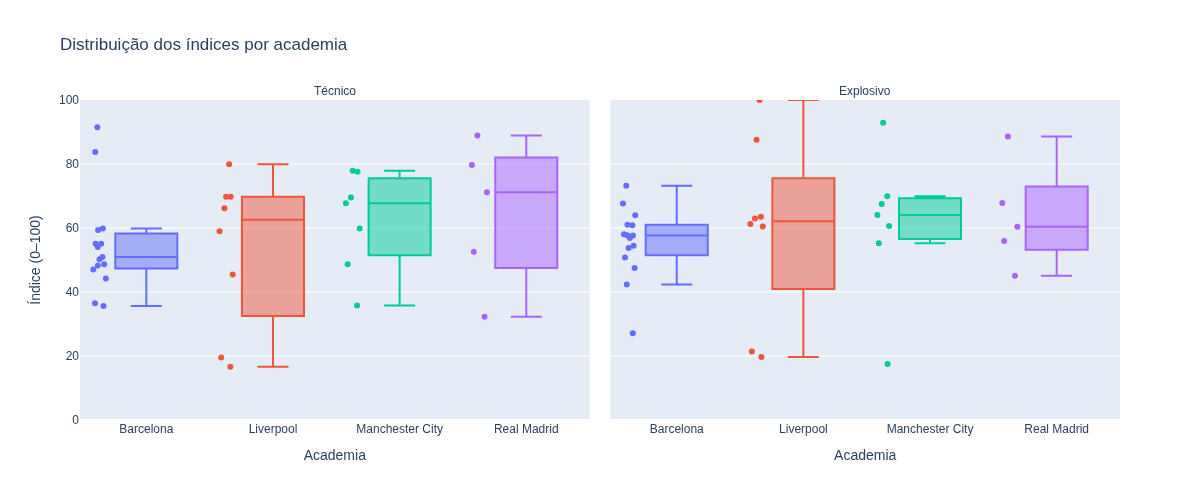

In [7]:
longos = indices.melt(
    id_vars=["player_id", "nome", "clube", "categoria"],
    value_vars=["indice_tecnico", "indice_explosivo"],
    var_name="perfil",
    value_name="indice",
).dropna(subset=["indice"])
longos["perfil"] = longos["perfil"].map({
    "indice_tecnico": "Técnico",
    "indice_explosivo": "Explosivo",
})

fig = px.box(
    longos,
    x="clube",
    y="indice",
    color="clube",
    facet_col="perfil",
    points="all",
    range_y=[0, 100],
    title="Distribuição dos índices por academia",
    labels={"clube": "Academia", "indice": "Índice (0–100)"},
)
fig.update_layout(showlegend=False)
fig.for_each_annotation(lambda anotacao: anotacao.update(text=anotacao.text.replace("perfil=", "")))
display(Image(data=fig.to_image(format="png", width=1200, scale=1)))

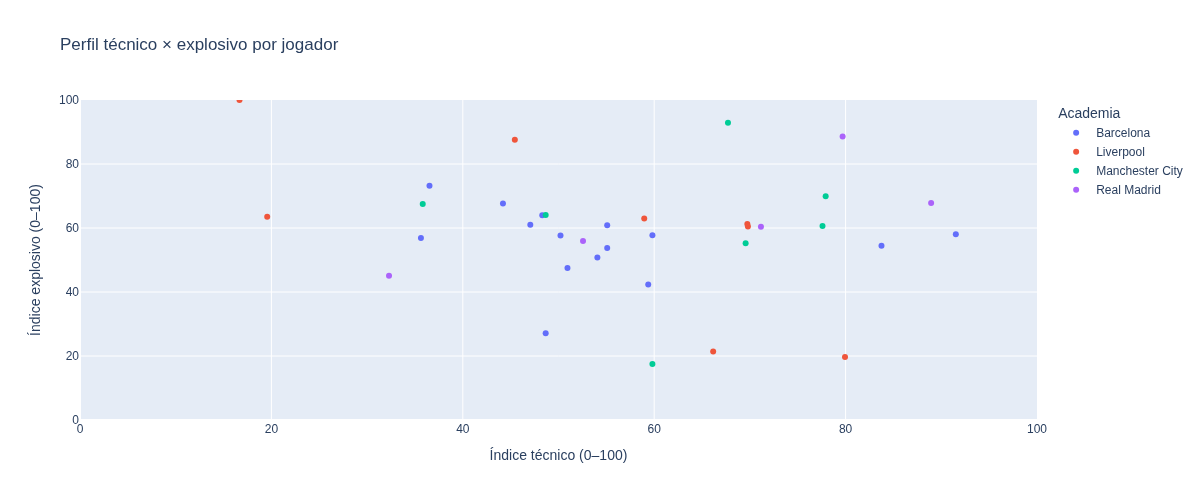

In [8]:
fig = px.scatter(
    indices,
    x="indice_tecnico",
    y="indice_explosivo",
    color="clube",
    hover_name="nome",
    hover_data=["categoria", "minutos"],
    range_x=[0, 100],
    range_y=[0, 100],
    title="Perfil técnico × explosivo por jogador",
    labels={
        "indice_tecnico": "Índice técnico (0–100)",
        "indice_explosivo": "Índice explosivo (0–100)",
        "clube": "Academia",
    },
)
display(Image(data=fig.to_image(format="png", width=1200, scale=1)))

## Cobertura e perguntas para a análise

A cobertura mostra quantos atletas têm dados disponíveis para cada métrica. Valores ausentes podem mudar a composição efetiva de uma comparação; por isso, devem acompanhar a leitura dos índices.

In [9]:
cobertura_exibicao = cobertura.copy()
cobertura_exibicao["ausentes"] = cobertura_exibicao["n_amostra"] - cobertura_exibicao["n_jogadores"]
cobertura_exibicao["cobertura_pct"] = (100 * cobertura_exibicao["proporcao_coberta"]).round(1)
display(cobertura_exibicao[["indice", "metrica", "n_jogadores", "ausentes", "cobertura_pct"]].sort_values(["indice", "metrica"]))

,indice,metrica,n_jogadores,ausentes,cobertura_pct
0,explosivo,aerialDuelsWon,34,1,97.1
1,explosivo,groundDuelsWon,34,1,97.1
2,explosivo,height_in_cm,35,0,100.0
3,explosivo,metersCoveredSprinting,30,5,85.7
4,explosivo,numberOfSprints,30,5,85.7
5,explosivo,successfulDribbles,34,1,97.1
6,tecnico,accurateFinalThirdPasses,34,1,97.1
7,tecnico,accuratePasses,34,1,97.1
8,tecnico,assists,35,0,100.0
9,tecnico,expectedAssists,33,2,94.3
